# Laboratorium 6 — przygotowanie danych dla Char-RNN

Korpus: *Lalka*, tom I (B. Prus), Wolne Lektury — domena publiczna.

## 1. Importy

In [1]:
!pip -q install torch numpy pandas matplotlib

In [2]:
import re
import json
import unicodedata
import urllib.request
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(0)
np.random.seed(0)

## 2. Pobranie korpusu

In [3]:
URL = 'https://wolnelektury.pl/media/book/txt/lalka-tom-pierwszy.txt'
surowy = urllib.request.urlopen(URL).read().decode('utf-8')
print('Długość surowego tekstu:', len(surowy))
print('--- POCZĄTEK ---')
print(repr(surowy[:500]))
print('--- KONIEC ---')
print(repr(surowy[-1200:]))

Długość surowego tekstu: 784082
--- POCZĄTEK ---
'Bolesław Prus\r\n\r\nLalka\r\n\r\nISBN 978-83-288-2673-1\r\n\r\n\r\n\r\n\r\n\r\nTom I\r\n\r\n\r\n\r\nI. Jak wygląda firma J. Mincel i S. Wokulski przez szkło butelek?\r\n\r\nW początkach roku 1878, kiedy świat polityczny zajmował się pokojem san-stefańskim, wyborem nowego papieża albo szansami europejskiej wojny, warszawscy kupcy tudzież inteligencja pewnej okolicy Krakowskiego Przedmieścia niemniej gorąco interesowała się przyszłością galanteryjnego sklepu pod firmą J. Mincel i S. Wokulski.\r\n\r\nW renomowanej jadłodajni, gdzie '
--- KONIEC ---
'ie zasoby Wolnych Lektur możesz swobodnie wykorzystywać, publikować i rozpowszechniać pod warunkiem zachowania warunków licencji i zgodnie z Zasadami wykorzystania Wolnych Lektur.\r\nTen utwór jest w domenie publicznej.\r\nWszystkie materiały dodatkowe (przypisy, motywy literackie) są udostępnione na Licencji Wolnej Sztuki 1.3: https://artlibre.org/licence/lal/pl/\r\nFundacja Wolne Lektury zas

## 3. Czyszczenie

In [4]:
def oczysc(t):
    t = unicodedata.normalize('NFC', t)
    t = t.replace('\r\n', '\n').replace('\r', '\n')
    stopka = t.rfind('\n-----')
    if stopka != -1:
        t = t[:stopka]
    isbn = re.search(r'ISBN[^\n]*\n', t[:3000])
    if isbn:
        t = t[isbn.end():]
    t = t.replace('\u00a0', ' ').replace('\ufeff', '')
    t = re.sub(r'[ \t]+', ' ', t)
    t = re.sub(r' *\n *', '\n', t)
    t = re.sub(r'\n{3,}', '\n\n', t)
    return t.strip()


tekst = oczysc(surowy)
print('Długość po czyszczeniu:', len(tekst), f'({len(tekst) / len(surowy):.1%} surowego)')
print('Znaczniki HTML:', len(re.findall(r'<[^>]+>', tekst)))
print('Adresy www:', len(re.findall(r'https?://|www\.', tekst)))
print('Wystąpienia "wolnelektury":', tekst.lower().count('wolnelektury'))

polskie = 'ąćęłńóśźżĄĆĘŁŃÓŚŹŻ'
licznik_calosc = Counter(tekst)
print('Polskie znaki:', {z: licznik_calosc[z] for z in polskie})

rzadkie = {z: n for z, n in licznik_calosc.items() if n < 20}
print('Rzadkie znaki (<20 wystąpień):', rzadkie)

Długość po czyszczeniu: 772586 (98.5% surowego)
Znaczniki HTML: 0
Adresy www: 0
Wystąpienia "wolnelektury": 0
Polskie znaki: {'ą': 7308, 'ć': 3069, 'ę': 10281, 'ł': 16128, 'ń': 741, 'ó': 4971, 'ś': 4769, 'ź': 429, 'ż': 6503, 'Ą': 0, 'Ć': 0, 'Ę': 0, 'Ł': 191, 'Ń': 0, 'Ó': 2, 'Ś': 41, 'Ź': 4, 'Ż': 183}
Rzadkie znaki (<20 wystąpień): {'7': 9, '6': 15, 'Ó': 2, '5': 16, '9': 8, 'V': 14, '4': 8, '3': 14, "'": 10, 'v': 17, 'Q': 1, 'à': 2, 'q': 2, 'é': 1, 'x': 1, '2': 8, '»': 8, '«': 6, 'X': 16, 'Ź': 4, 'ü': 1, 'ö': 3, 'Y': 15, 'ç': 1}


In [5]:
print('--- początek ---')
print(tekst[:400])
print('\n--- środek ---')
print(tekst[len(tekst) // 2: len(tekst) // 2 + 400])
print('\n--- koniec ---')
print(tekst[-400:])

--- początek ---
Tom I

I. Jak wygląda firma J. Mincel i S. Wokulski przez szkło butelek?

W początkach roku 1878, kiedy świat polityczny zajmował się pokojem san-stefańskim, wyborem nowego papieża albo szansami europejskiej wojny, warszawscy kupcy tudzież inteligencja pewnej okolicy Krakowskiego Przedmieścia niemniej gorąco interesowała się przyszłością galanteryjnego sklepu pod firmą J. Mincel i S. Wokulski.

W 

--- środek ---
ść…

Uścisnął Wokulskiemu rękę, zbiegł ze wzgórza i zniknął między drzewami.

Na Ogród Botaniczny i na Łazienki zapadał już mrok.

„Wariat czy geniusz?… — szepnął Wokulski czując, że sam jest w najwyższym stopniu rozstrojony. — A jeżeli geniusz?…”

Wstał i poszedł w głąb ogrodu, między spacerujących ludzi. Zdawało mu się, że nad pagórkiem, z którego uciekł, unosi się jakaś święta groza.

W Ogrodzi

--- koniec ---
 miesięcy po jego powrocie jedna stara plotkarka (pani Meliton) powiedziała mi, że Stach jest zakochany…

Roześmiałem się z tej gawędy, bo przecież k

## 4. Podział na trening / walidację / test

Tekst dzielę na trzy rozłączne, ciągłe fragmenty **przed** tworzeniem okien. Granice przesuwam do najbliższego końca akapitu.

In [6]:
PROPORCJE = {'train': 0.8, 'val': 0.1, 'test': 0.1}


def granica(t, poz):
    k = t.find('\n\n', poz)
    return k + 2 if k != -1 else poz


N = len(tekst)
g1 = granica(tekst, int(N * PROPORCJE['train']))
g2 = granica(tekst, int(N * (PROPORCJE['train'] + PROPORCJE['val'])))

czesci = {
    'train': tekst[:g1],
    'val': tekst[g1:g2],
    'test': tekst[g2:],
}

assert sum(len(c) for c in czesci.values()) == N
for nazwa, c in czesci.items():
    print(f'{nazwa:5s}: {len(c):7d} znaków ({len(c) / N:.1%}), początek: {c[:60]!r}')

train:  618105 znaków (80.0%), początek: 'Tom I\n\nI. Jak wygląda firma J. Mincel i S. Wokulski przez sz'
val  :   77475 znaków (10.0%), początek: '— Nic o tym nie wiem — odpowiedział Szlangbaum spuszczając o'
test :   77006 znaków (10.0%), początek: '— Szpigelman?… Ach, prawda!… Zapomniałam o nim. Powiedz mu, '


## 5. Słownik (budowany tylko na treningu) i znaki spoza słownika

In [7]:
UNK = '¤'
assert UNK not in tekst

znaki = sorted(set(czesci['train'])) + [UNK]
stoi = {z: i for i, z in enumerate(znaki)}
itos = {i: z for z, i in stoi.items()}
V = len(znaki)
UNK_ID = stoi[UNK]


def enc(s):
    return [stoi.get(c, UNK_ID) for c in s]


def dec(ids):
    return ''.join(itos[int(i)] for i in ids)


print('Rozmiar słownika V (z UNK):', V)
print('Znaki:', repr(''.join(znaki)))

oov = {}
for nazwa, c in czesci.items():
    poza = Counter(z for z in c if z not in stoi)
    oov[nazwa] = sum(poza.values())
    print(f'{nazwa:5s}: znaki spoza słownika -> {dict(poza)} (razem {oov[nazwa]})')

zmapowane = {n: ''.join(z if z in stoi else UNK for z in c) for n, c in czesci.items()}
dane = {n: np.array(enc(c), dtype=np.int64) for n, c in czesci.items()}

Rozmiar słownika V (z UNK): 102
Znaki: "\n !'()*,-.0123456789:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz«»ÓàçéóöüąćęŁłńŚśŹźŻż–—”„…¤"
train: znaki spoza słownika -> {} (razem 0)
val  : znaki spoza słownika -> {} (razem 0)
test : znaki spoza słownika -> {} (razem 0)


In [8]:
fragment = czesci['train'][5000:5120]
ids = enc(fragment)
print('Fragment :', repr(fragment))
print('ID       :', ids[:30], '...')
print('Odkodowany:', repr(dec(ids)))
assert dec(ids) == fragment
assert dec(dane['train']) == czesci['train']
for nazwa in ['val', 'test']:
    assert dec(dane[nazwa]) == zmapowane[nazwa]
print('Test kodowania i dekodowania: OK (trening odtworzony 1:1, val/test zgodne po mapowaniu na UNK)')

Fragment : 'j gniewał się, jeżeli nazwał go kto „panem konsyliarzem”. Raz tak zwymyślał gościa, że mało obaj nie porwali się za czub'
ID       : [58, 1, 55, 62, 57, 53, 71, 49, 88, 1, 67, 57, 86, 7, 1, 58, 53, 95, 53, 60, 57, 1, 62, 49, 74, 71, 49, 88, 1, 55] ...
Odkodowany: 'j gniewał się, jeżeli nazwał go kto „panem konsyliarzem”. Raz tak zwymyślał gościa, że mało obaj nie porwali się za czub'
Test kodowania i dekodowania: OK (trening odtworzony 1:1, val/test zgodne po mapowaniu na UNK)


## 6. Dataset i DataLoader dla każdego zbioru

In [9]:
class DatasetZnakowy(Dataset):
    def __init__(self, dane, sekw):
        self.dane = torch.as_tensor(dane, dtype=torch.long)
        self.sekw = sekw

    def __len__(self):
        return max(0, len(self.dane) - self.sekw)

    def __getitem__(self, i):
        x = self.dane[i:i + self.sekw]
        y = self.dane[i + 1:i + self.sekw + 1]
        return x, y


SEKW = 100
BATCH = 64

datasety = {n: DatasetZnakowy(d, SEKW) for n, d in dane.items()}
loadery = {
    'train': DataLoader(datasety['train'], batch_size=BATCH, shuffle=True, drop_last=True,
                        generator=torch.Generator().manual_seed(0)),
    'val': DataLoader(datasety['val'], batch_size=BATCH, shuffle=False, drop_last=False),
    'test': DataLoader(datasety['test'], batch_size=BATCH, shuffle=False, drop_last=False),
}

for n in datasety:
    print(f'{n:5s}: par = {len(datasety[n]):7d}, batchy = {len(loadery[n]):5d}')

train: par =  618005, batchy =  9656
val  : par =   77375, batchy =  1209
test : par =   76906, batchy =  1202


## 7. Kontrola batchy

In [10]:
for nazwa in ['train', 'val', 'test']:
    xb, yb = next(iter(loadery[nazwa]))
    assert xb.shape == yb.shape and xb.shape[1] == SEKW
    assert xb.dtype == torch.int64 and yb.dtype == torch.int64
    assert xb.min() >= 0 and xb.max() < V and yb.min() >= 0 and yb.max() < V
    assert torch.equal(xb[:, 1:], yb[:, :-1])

    i = len(datasety[nazwa]) // 2
    x, y = datasety[nazwa][i]
    zrodlo = zmapowane[nazwa]
    assert dec(x) == zrodlo[i:i + SEKW]
    assert dec(y) == zrodlo[i + 1:i + SEKW + 1]
    assert dec(y)[-1] == zrodlo[i + SEKW]

    print(f'=== {nazwa} ===')
    print('X:', tuple(xb.shape), xb.dtype, ' Y:', tuple(yb.shape), yb.dtype,
          f' zakres ID: [{int(xb.min())}, {int(xb.max())}]')
    print(f'Para i={i}:')
    print('  wejście:', repr(dec(x)))
    print('  cel    :', repr(dec(y)))
    print(f'  ostatni znak celu: {dec(y)[-1]!r} == tekst[{i + SEKW}]: {zrodlo[i + SEKW]!r}')
    print()
print('Wszystkie kontrole przeszły.')

=== train ===
X: (64, 100) torch.int64  Y: (64, 100) torch.int64  zakres ID: [0, 100]
Para i=309002:
  wejście: 'rawą nóżkę, potem lewą nóżkę, potem wystawia rączki… Wszystko w tym celu, ażeby złapać Stacha, a jeg'
  cel    : 'awą nóżkę, potem lewą nóżkę, potem wystawia rączki… Wszystko w tym celu, ażeby złapać Stacha, a jego'
  ostatni znak celu: 'o' == tekst[309102]: 'o'

=== val ===
X: (64, 100) torch.int64  Y: (64, 100) torch.int64  zakres ID: [0, 99]
Para i=38687:
  wejście: ' Ten dom można było kupić za siedemdziesiąt jeden tysięcy. On dziś więcej niewart…\n\n— Dla jednego ni'
  cel    : 'Ten dom można było kupić za siedemdziesiąt jeden tysięcy. On dziś więcej niewart…\n\n— Dla jednego nie'
  ostatni znak celu: 'e' == tekst[38787]: 'e'

=== test ===
X: (64, 100) torch.int64  Y: (64, 100) torch.int64  zakres ID: [0, 100]
Para i=38453:
  wejście: 'ony mówca nagle ochłonął i skoczywszy w jakąś dorożkę kazał odwieźć się do domu.\n\nStach był już chyb'
  cel    : 'ny mówca nagle ochło

## 8. Statystyki zbiorów

In [11]:
wiersze = []
for n, c in czesci.items():
    wiersze.append({
        'zbiór': n,
        'znaki': len(c),
        'udział [%]': round(100 * len(c) / N, 2),
        'różne znaki': len(set(c)),
        'znaki OOV': oov[n],
        f'pary (SEKW={SEKW})': len(datasety[n]),
        f'batche (B={BATCH})': len(loadery[n]),
    })
statystyki = pd.DataFrame(wiersze).set_index('zbiór')
statystyki

,znaki,udział [%],różne znaki,znaki OOV,pary (SEKW=100),batche (B=64)
zbiór,,,,,,
train,618105,80.00,101,0,618005,9656
val,77475,10.03,74,0,77375,1209
test,77006,9.97,81,0,76906,1202


## 9. Najczęstsze znaki w treningu

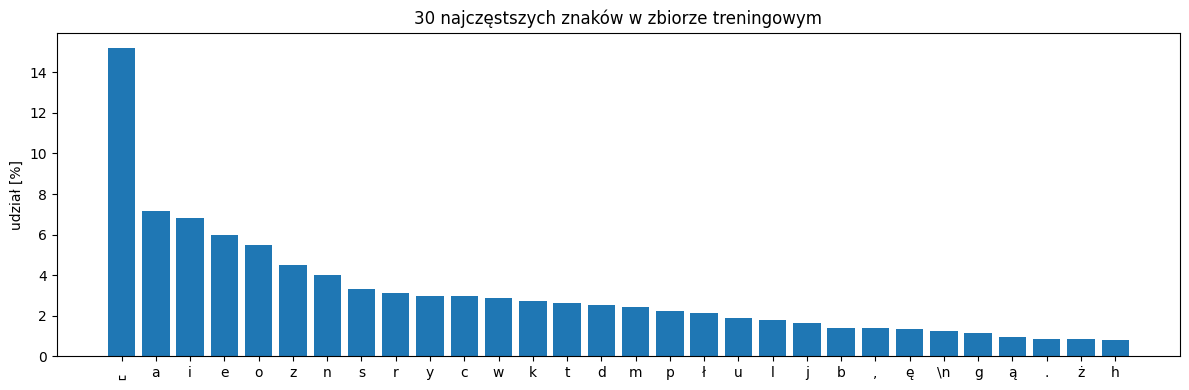

znak  liczba  udział [%]
   ␣   93890       15.19
   a   44131        7.14
   i   42211        6.83
   e   37054        5.99
   o   34045        5.51
   z   27753        4.49
   n   24709        4.00
   s   20501        3.32
   r   19290        3.12
   y   18477        2.99
   c   18331        2.97
   w   17755        2.87
   k   16789        2.72
   t   16102        2.61
   d   15481        2.50


In [12]:
def etykieta(z):
    return {' ': '␣', '\n': '\\n'}.get(z, z)


licznik_train = Counter(czesci['train'])
top = licznik_train.most_common(30)
suma = sum(licznik_train.values())

plt.figure(figsize=(12, 4))
plt.bar([etykieta(z) for z, _ in top], [100 * n / suma for _, n in top])
plt.ylabel('udział [%]')
plt.title('30 najczęstszych znaków w zbiorze treningowym')
plt.tight_layout()
plt.savefig('top_znaki.png', dpi=150)
plt.show()

print(pd.DataFrame([(etykieta(z), n, round(100 * n / suma, 2)) for z, n in top[:15]],
                   columns=['znak', 'liczba', 'udział [%]']).to_string(index=False))

## 10. Wpływ długości okna SEKW na liczbę par

      train pary  train batche  val pary  val batche  test pary  test batche
SEKW                                                                        
25        618080          9657     77450        1211      76981         1203
50        618055          9657     77425        1210      76956         1203
100       618005          9656     77375        1209      76906         1202
200       617905          9654     77275        1208      76806         1201
400       617705          9651     77075        1205      76606         1197


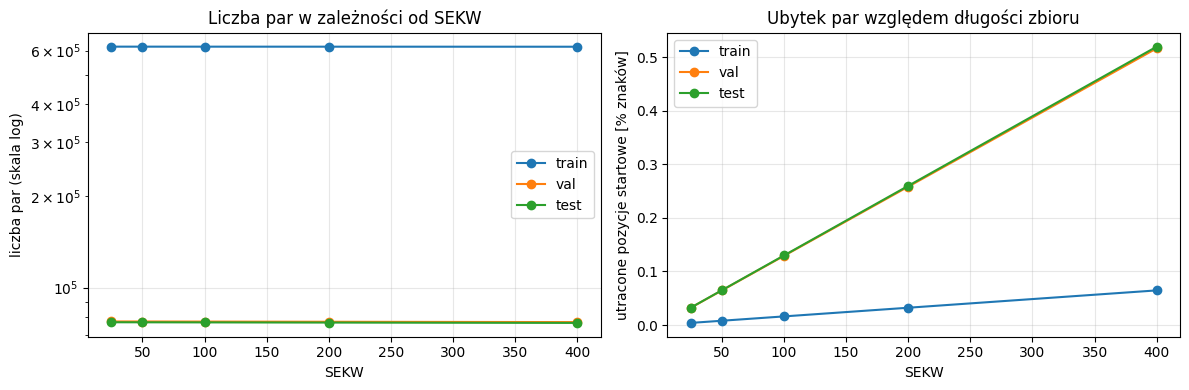

In [13]:
SEKWY = [25, 50, 100, 200, 400]

wyniki = []
for s in SEKWY:
    wiersz = {'SEKW': s}
    for n, d in dane.items():
        ds_s = DatasetZnakowy(d, s)
        wiersz[f'{n} pary'] = len(ds_s)
        wiersz[f'{n} batche'] = len(DataLoader(ds_s, batch_size=BATCH, drop_last=(n == 'train')))
    wyniki.append(wiersz)

sekw_df = pd.DataFrame(wyniki).set_index('SEKW')
print(sekw_df.to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for n in dane:
    ax[0].plot(SEKWY, sekw_df[f'{n} pary'], marker='o', label=n)
    ax[1].plot(SEKWY, 100 * (len(dane[n]) - sekw_df[f'{n} pary']) / len(dane[n]), marker='o', label=n)
ax[0].set_yscale('log')
ax[0].set_xlabel('SEKW')
ax[0].set_ylabel('liczba par (skala log)')
ax[0].set_title('Liczba par w zależności od SEKW')
ax[1].set_xlabel('SEKW')
ax[1].set_ylabel('utracone pozycje startowe [% znaków]')
ax[1].set_title('Ubytek par względem długości zbioru')
for a in ax:
    a.legend()
    a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('pary_vs_sekw.png', dpi=150)
plt.show()

## 11. Dla chętnych: najczęstsze słowa i długości słów (trening)

Liczba słów: 93214  różnych: 19540


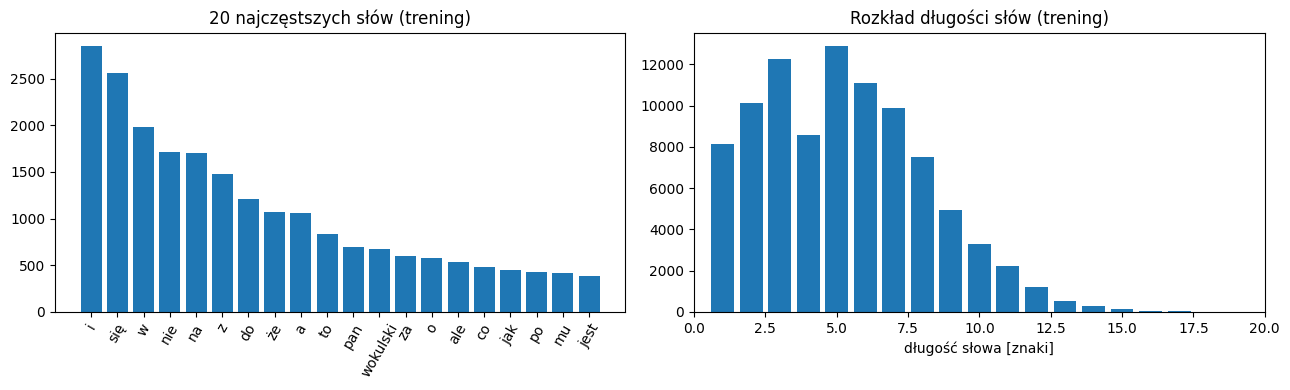

Średnia długość słowa: 5.27
Top 20: [('i', 2849), ('się', 2560), ('w', 1984), ('nie', 1712), ('na', 1698), ('z', 1475), ('do', 1210), ('że', 1074), ('a', 1062), ('to', 830), ('pan', 691), ('wokulski', 670), ('za', 597), ('o', 573), ('ale', 538), ('co', 481), ('jak', 445), ('po', 426), ('mu', 416), ('jest', 384)]


In [14]:
slowa = re.findall(r'[a-ząćęłńóśźż]+', czesci['train'].lower())
licznik_slow = Counter(slowa)
print('Liczba słów:', len(slowa), ' różnych:', len(licznik_slow))

top_slowa = licznik_slow.most_common(20)
dlugosci = Counter(len(w) for w in slowa)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar([w for w, _ in top_slowa], [n for _, n in top_slowa])
ax[0].set_title('20 najczęstszych słów (trening)')
ax[0].tick_params(axis='x', rotation=60)
ax[1].bar(sorted(dlugosci), [dlugosci[k] for k in sorted(dlugosci)])
ax[1].set_xlim(0, 20)
ax[1].set_xlabel('długość słowa [znaki]')
ax[1].set_title('Rozkład długości słów (trening)')
plt.tight_layout()
plt.savefig('slowa.png', dpi=150)
plt.show()

print('Średnia długość słowa:', round(np.mean([len(w) for w in slowa]), 2))
print('Top 20:', top_slowa)

## 12. Zapis podziału i słownika na laboratorium 7

In [15]:
katalog = Path('dane_lab6')
katalog.mkdir(exist_ok=True)
for n, c in czesci.items():
    (katalog / f'{n}.txt').write_text(c, encoding='utf-8')

(katalog / 'slownik.json').write_text(json.dumps({
    'zrodlo': URL,
    'proporcje': PROPORCJE,
    'granice': [0, g1, g2, N],
    'unk': UNK,
    'znaki': znaki,
}, ensure_ascii=False, indent=1), encoding='utf-8')

print('Zapisane pliki:', sorted(p.name for p in katalog.iterdir()))

Zapisane pliki: ['slownik.json', 'test.txt', 'train.txt', 'val.txt']
